**Hueristic method:**

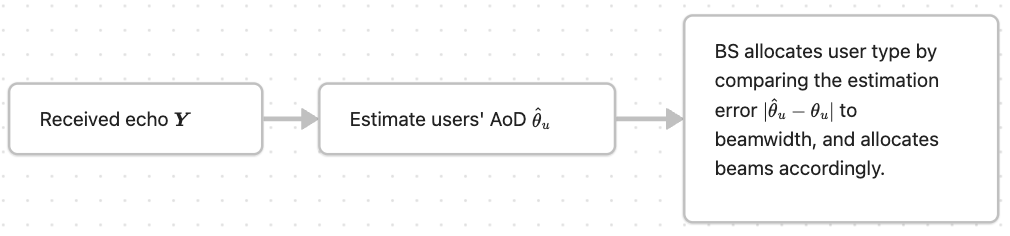

It uses a genie information: the true AoD.

### Reinforcement Learning
**State** $$\mathcal{S} = \left\{[\boldsymbol{b}(t-2), \boldsymbol{b}(t-1), \boldsymbol{b}(t)], [B_1, \cdots, B_U], [\text{Total packets}], [\lambda_1,\cdots, \lambda_U]\right\}$$

where $\boldsymbol{b}_f$ is the averaged beamforming output. $\boldsymbol{b}_u = \mathrm{E}(\boldsymbol{f}_u^H \boldsymbol{Y})$. 

**Action** 
The action space is simplified.
$$a_n = \left\{ [\lambda_1, \cdots, \lambda_U], [\mathcal{C}_1, \cdots, \mathcal{C}_U]\right\}$$
For a single user, the action space is 2.
- $\lambda_u = 1$: the beam $\mathcal{C}_{u, n} = \mathcal{C}_{u, n-1}$, or the beam $\mathcal{C}_{u, n}$ is the beam from the estimation result 

- $\lambda_u = 0$:  $\mathcal{C}_{u, n} = \min(\mathcal{C}_{u, n-1}) + [-1,0, 1]$

The total action space is $2^U$.

**Reward**
$$r = \sum_{u=1}^U(1 + \frac{\text{Transmitted packets}}{\text{Total packets}} )(R_u>4) \lambda_u$$

Training: there are only 6 possible initial user locations 
Testing: users can start from anywhere

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


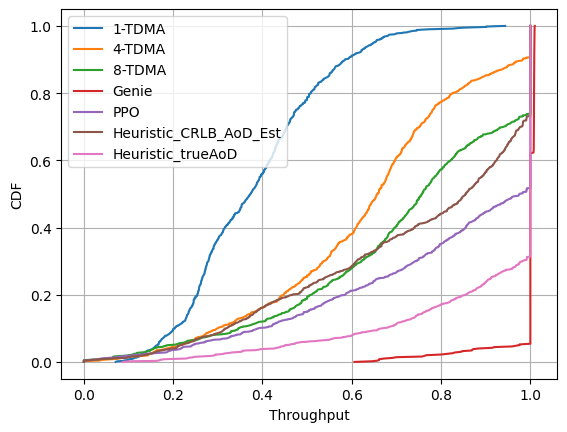

In [3]:
import numpy as np
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
for N in [1,4,8]:
    th = np.loadtxt('Multi-user-BM/results_bm/Thp_' + str(N) + 'TDMA')
    th_cdf = np.sort(th)
    yvals = np.arange(len(th))/float(len(th)-1)
    ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_Genie')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_PPO')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_Heuristic_crlb_aod_est')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_Heuristic_genie')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
ax.legend(['1-TDMA','4-TDMA','8-TDMA', 'Genie','PPO', 'Heuristic_CRLB_AoD_Est', 'Heuristic_trueAoD'])
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()
plt.savefig('throughput.eps',format='eps')

**X-TDMA** 
$X$-TDMA denotes that the BS assign a sensing slot of every user before every $X$ communication slots. 

In the above figure, users' speed $v\sim\mathcal{N}(20,2)$. 

Users's speed is $v\sim\mathcal{N}(30,2)$. The PPO still uses the model trained from $v\sim\mathcal{N}(20,2)$

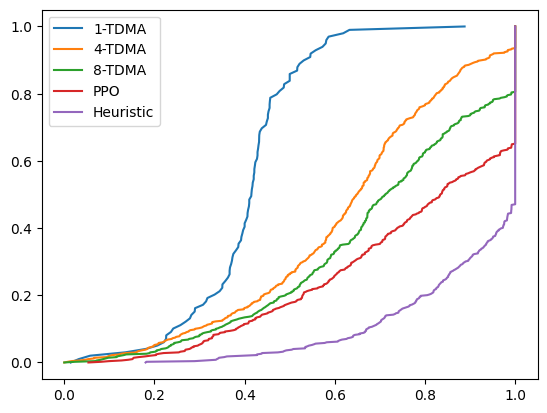

In [16]:
fig, ax = plt.subplots()
for N in [1,4,8]:
    th = np.loadtxt('Multi-user-BM/results_bm/Thp_' + str(N) + 'TDMA_v=30')
    th_cdf = np.sort(th)
    yvals = np.arange(len(th))/float(len(th)-1)
    ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_PPO_v=30')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_heuristic_v=30')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
ax.legend(['1-TDMA','4-TDMA','8-TDMA', 'PPO','Heuristic'])
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

The PPO cannot outperform the Heuristic method because the heuristic method uses the true AoD information of the users.

Ways to avoid using true information in the Heuristic method:

- calcuate the Bayesian cramer rao bound. Consider the uniform distribution as prior information for AoD 

- calculate an estimate of CRB considering the previous estimate as mean and CRB as variance

- calculate an estimate of CRB using the previous estimate

TODO:
- check other reward functions 

- check make the action space more complicated

- consider the sensing metric 

1. Check reward functions: 

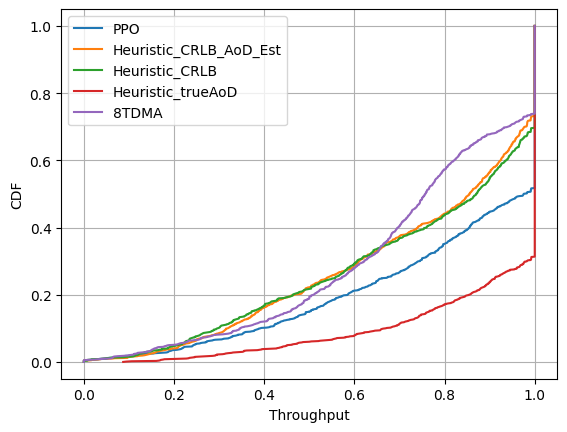

In [2]:
import numpy as np
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
th = np.loadtxt('Multi-user-BM/results_bm/Thp_PPO')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_Heuristic_crlb_aod_est')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_Heuristic_crlb')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_Heuristic_genie')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_8TDMA')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')

ax.legend(['PPO', 'Heuristic_CRLB_AoD_Est', 'Heuristic_CRLB', 'Heuristic_trueAoD', '8TDMA'])
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()


Text(0, 0.5, 'CDF')

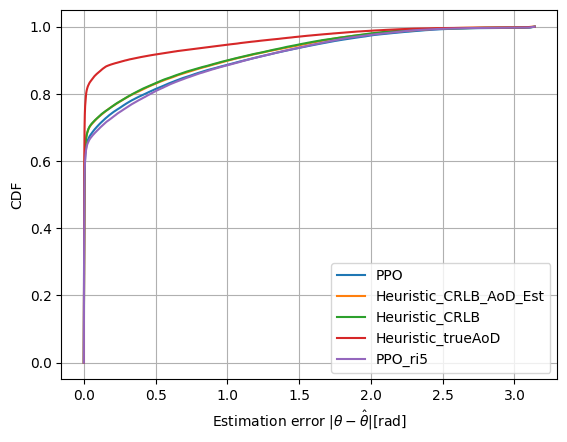

In [14]:
import numpy as np
import matplotlib.pyplot as plt
# Estimation error CDF
fig, ax = plt.subplots()
files = ['Multi-user-BM/results_bm/Er_PPO', 'Multi-user-BM/results_bm/Er_Heuristic_crlb_aod_est', 'Multi-user-BM/results_bm/Er_Heuristic_crlb', 'Multi-user-BM/results_bm/Er_Heuristic_genie','Multi-user-BM/results_bm/Er_PPO_test']
for file in files:
    err = np.loadtxt(file)
    er = np.concatenate(err).ravel().tolist()
    data_cdf = np.sort(er)
    yvals = np.arange(len(data_cdf))/float(len(data_cdf)-1)
    ax.plot(data_cdf, yvals, '-')
ax.legend(['PPO', 'Heuristic_CRLB_AoD_Est', 'Heuristic_CRLB', 'Heuristic_trueAoD','PPO_ri5'])
ax.grid()
ax.set_xlabel('Estimation error '+ r'$|\theta - \hat{\theta}|$[rad]')
ax.set_ylabel('CDF')

In [ ]:
self.initial_pos_training = np.array([[20., 72.], [31., 18.],[60., 69.],[78.,  7.],[87., 68.]], 
[[24., 12.], [27., 91.], [44.,65.],[78., 11.],[80. ,81.]],
[[11. ,26.],[25., 12.],[36. ,25.],[68. ,29.],[81. ,77.]],
[[15. ,69.],[26., 18.],[45., 27.],[79., 40.],[85. ,65.]],
[[12., 72.], [27.,96.],[58., 32.],[78. ,97.],[88., 34.]], 
[[22., 48.],[31., 70.],[62., 33.],[72., 70.],[81.,  8.]] )

self.config = np.array([[0, 0],[2, 2],[1, 1],[4, 2],[1, 1]], 
                       [[2, 2],[3, 3],[4, 2],[4, 2],[4, 2]],
                        [[0, 0],[2, 2],[1, 1],[1 ,1],[4, 2]],
                         [[0 ,0],[2, 2],[1, 1],[4, 2],[4, 2]],
                          [[0, 0], [3, 3],[4 ,2],[4 ,2],[4, 2]],
                           [[4, 2],[4, 2],[4, 2],[1, 1],[4, 2]] )

self.if_turned = [False, False, False, False, False]

Using CRLB as the criterion for deciding user type decreases the throughput performance. 
CRLB is the lower bound of estimation error variance. The estimation error variance is larger than CRLB, meaning the estimation error is large than square root of CRLB.
It is a small value compared to the real estimation error. Thereafter, it is often smaller than beamwidth such that the user is set as the communication user. 

Ramoni's comment during the last meeting:
    how is the beam calculated when the user changes from a sensing user to a communication user?

*Before: the beam is calculated from the estimated AoD $\hat{\theta}$, that is, the BS needs to estimate the AoD.
Now: the BS uses the information of transmitted beam and the reflected echo, that is, the BS selects the beam from the multiple transmitted sensing beams which maximizes the beamforming output of the reflected echo.  *
However, the BS needs to estimate AoD for calculating the CRLB.


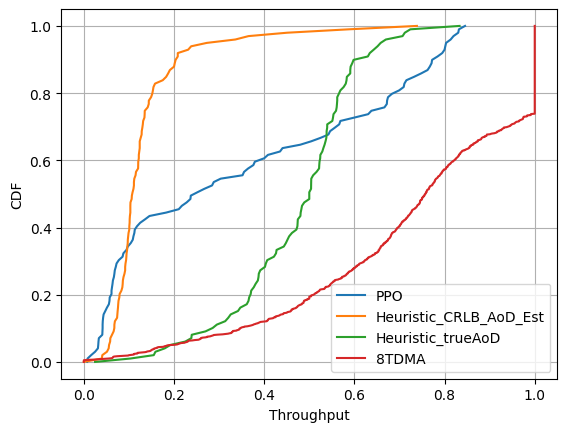

In [2]:
import numpy as np
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
th = np.loadtxt('Multi-user-BM/results_bm/Thp_PPO')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_Heuristic_crlb_aod_est')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_genie')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
# th = np.loadtxt('Multi-user-BM/results_bm/Thp_8TDMA')
# th_cdf = np.sort(th)
# yvals = np.arange(len(th))/float(len(th)-1)
# ax.plot(th_cdf, yvals, '-')
ax.legend(['PPO', 'Heuristic_CRLB_AoD_Est','Heuristic_trueAoD', '8TDMA'])
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

What is the contribution of the paper?

For the mis-alignment problem, in 3GPP protocol, it requies users report to the base station. The BS sweep beams to the user and conduct the beam re-alignment. To prevent beam mis-alignment, the BS normally sweep the beams periodically, which refers to TDMA. 
In this work, we consider that the BS minimizes beam-misalignment utilizing only the reflected echo at its sensing receiver.
- proposed a heuristic method that assign user type and beams according to the AoD estimates from the echo



The remianing problem:
- The objective funtion actually did not consider the sensing.
- Power calculation - use traditional method
- Channel model is not realistic, only consider the direct path

